# TTS Model Evaluation

This notebook evaluates pretrained TTS models using inference latency,
Real-Time Factor (RTF), and generated audio validity.

Two experiments are conducted:
1. Glow-TTS vs Tacotron2-DDC
2. Glow-TTS CPU vs GPU performance

In [1]:
%pip install -q "coqui-tts[languages]" soundfile pandas

In [2]:
import os
import gc
import json
import time
import platform
import random
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import soundfile as sf
import torch

from TTS.api import TTS

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4


## Experiment 1: Pretrained TTS Model Comparison

Glow-TTS and Tacotron2-DDC are evaluated using the same five
English sentences. Each sentence is generated three times after
a warm-up run.

RTF is calculated as inference latency divided by generated
audio duration. Lower RTF indicates faster synthesis.

In [3]:
TEST_SENTENCES = [
    "The quick brown fox jumps over the lazy dog.",
    "Hello, welcome to our text to speech experiment.",
    "Today is a beautiful day to learn something new.",
    "Artificial intelligence can transform written text into speech.",
    "Please read this sentence clearly and naturally."
]

MODELS = {
    "Glow-TTS": "tts_models/en/ljspeech/glow-tts",
    "Tacotron2-DDC": "tts_models/en/ljspeech/tacotron2-DDC"
}

OUTPUT_DIR = Path("/content/tts_evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_REPEATS = 3

print("Number of test sentences:", len(TEST_SENTENCES))
print("Repeats per sentence:", N_REPEATS)
print("Models:", list(MODELS.keys()))
print("Output directory:", OUTPUT_DIR)

Number of test sentences: 5
Repeats per sentence: 3
Models: ['Glow-TTS', 'Tacotron2-DDC']
Output directory: /content/tts_evaluation


In [4]:
def synchronize_device():
    """Ensure GPU operations finish before recording elapsed time."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def get_sample_rate(tts):
    """Get the model's output sample rate."""
    sr = getattr(tts.synthesizer, "output_sample_rate", None)

    if sr is None:
        sr = tts.synthesizer.tts_config.audio.sample_rate

    return int(sr)


def generate_audio(tts, text):
    """Generate waveform and measure inference latency."""
    synchronize_device()
    start_time = time.perf_counter()

    waveform = tts.tts(text=text)

    synchronize_device()
    elapsed = time.perf_counter() - start_time

    waveform = np.asarray(waveform, dtype=np.float32).reshape(-1)

    if waveform.size == 0:
        raise ValueError("The model generated an empty waveform.")

    if not np.isfinite(waveform).all():
        raise ValueError("The waveform contains NaN or infinite values.")

    return waveform, elapsed


def evaluate_model(model_label, model_name):
    """Evaluate one model using the shared test protocol."""
    print(f"\n{'=' * 65}")
    print(f"Evaluating: {model_label}")
    print(f"Model identifier: {model_name}")
    print(f"{'=' * 65}")

    model_dir = OUTPUT_DIR / model_label.lower().replace("-", "_")
    model_dir.mkdir(parents=True, exist_ok=True)

    tts = TTS(
        model_name=model_name,
        progress_bar=True
    ).to(DEVICE)

    sample_rate = get_sample_rate(tts)
    print("Output sample rate:", sample_rate)

    # Warm-up: excluded from the measured results.
    print("Running warm-up...")
    warmup_audio, _ = generate_audio(tts, TEST_SENTENCES[0])
    del warmup_audio

    records = []

    for sentence_idx, sentence in enumerate(TEST_SENTENCES, start=1):
        print(f"\nSentence {sentence_idx}/{len(TEST_SENTENCES)}")
        print("Text:", sentence)

        latencies = []
        durations = []
        rtfs = []
        final_waveform = None

        for run_idx in range(1, N_REPEATS + 1):
            waveform, latency = generate_audio(tts, sentence)

            duration = len(waveform) / sample_rate

            if duration <= 0:
                raise ValueError("Generated audio has invalid duration.")

            rtf = latency / duration

            latencies.append(latency)
            durations.append(duration)
            rtfs.append(rtf)
            final_waveform = waveform

            print(
                f"  Run {run_idx}: "
                f"latency={latency:.4f}s, "
                f"duration={duration:.3f}s, "
                f"RTF={rtf:.4f}"
            )

        # Save one playable WAV per test sentence.
        wav_path = model_dir / f"sentence_{sentence_idx:02d}.wav"

        sf.write(
            str(wav_path),
            final_waveform,
            sample_rate,
            subtype="PCM_16"
        )

        # Reopen the WAV to validate the saved file.
        saved_audio, saved_sr = sf.read(str(wav_path))

        if saved_audio.size == 0:
            raise ValueError(f"Saved WAV is empty: {wav_path}")

        if saved_sr != sample_rate:
            raise ValueError(f"Sample-rate mismatch: {wav_path}")

        if not np.isfinite(saved_audio).all():
            raise ValueError(f"Invalid numeric audio values: {wav_path}")

        records.append({
            "model": model_label,
            "model_id": model_name,
            "sentence_id": sentence_idx,
            "text": sentence,
            "sample_rate": sample_rate,
            "repeat_count": N_REPEATS,
            "latency_mean_sec": float(np.mean(latencies)),
            "latency_std_sec": float(np.std(latencies, ddof=1))
                if len(latencies) > 1 else 0.0,
            "duration_mean_sec": float(np.mean(durations)),
            "rtf_mean": float(np.mean(rtfs)),
            "rtf_std": float(np.std(rtfs, ddof=1))
                if len(rtfs) > 1 else 0.0,
            "wav_path": str(wav_path),
            "wav_size_bytes": wav_path.stat().st_size,
            "wav_valid": True
        })

        print("Saved:", wav_path)
        print("WAV size:", wav_path.stat().st_size, "bytes")

        del final_waveform

    del tts
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return records

In [5]:
all_records = []

for model_label, model_name in MODELS.items():
    try:
        model_records = evaluate_model(model_label, model_name)
        all_records.extend(model_records)

    except Exception as exc:
        print(f"\nERROR while evaluating {model_label}:")
        print(type(exc).__name__, str(exc))

if not all_records:
    raise RuntimeError(
        "No model was evaluated successfully. "
        "Check the installation and model-loading errors above."
    )

results_df = pd.DataFrame(all_records)

print("\nEvaluation completed.")
print("Successful model-sentence evaluations:", len(results_df))

display(results_df)

expected_models = set(MODELS.keys())
evaluated_models = set(results_df["model"].unique())

assert evaluated_models == expected_models, (
    f"Missing models: {expected_models - evaluated_models}"
)

assert len(results_df) == len(MODELS) * len(TEST_SENTENCES), (
    "Incomplete model evaluation results."
)

assert results_df["wav_valid"].all()

print("All model evaluations completed successfully.")


Evaluating: Glow-TTS
Model identifier: tts_models/en/ljspeech/glow-tts


Output sample rate: 22050
Running warm-up...



Sentence 1/5
Text: The quick brown fox jumps over the lazy dog.
  Run 1: latency=0.1892s, duration=3.728s, RTF=0.0507
  Run 2: latency=0.1806s, duration=3.728s, RTF=0.0485
  Run 3: latency=0.1079s, duration=3.728s, RTF=0.0290
Saved: /content/tts_evaluation/glow_tts/sentence_01.wav
WAV size: 164428 bytes

Sentence 2/5
Text: Hello, welcome to our text to speech experiment.
  Run 1: latency=0.3882s, duration=3.704s, RTF=0.1048
  Run 2: latency=0.0849s, duration=3.704s, RTF=0.0229
  Run 3: latency=0.0537s, duration=3.704s, RTF=0.0145
Saved: /content/tts_evaluation/glow_tts/sentence_02.wav
WAV size: 163404 bytes

Sentence 3/5
Text: Today is a beautiful day to learn something new.
  Run 1: latency=0.1608s, duration=3.704s, RTF=0.0434
  Run 2: latency=0.0535s, duration=3.704s, RTF=0.0145
  Run 3: latency=0.0521s, duration=3.704s, RTF=0.0141
Saved: /content/tts_evaluation/glow_tts/sentence_03.wav
WAV size: 163404 bytes

Sentence 4/5
Text: Artificial intelligence can transform written text int


Evaluating: Tacotron2-DDC
Model identifier: tts_models/en/ljspeech/tacotron2-DDC
Output sample rate: 22050
Running warm-up...

Sentence 1/5
Text: The quick brown fox jumps over the lazy dog.
  Run 1: latency=0.3499s, duration=3.635s, RTF=0.0963
  Run 2: latency=0.3729s, duration=3.646s, RTF=0.1023
  Run 3: latency=0.4457s, duration=3.565s, RTF=0.1250
Saved: /content/tts_evaluation/tacotron2_ddc/sentence_01.wav
WAV size: 157260 bytes

Sentence 2/5
Text: Hello, welcome to our text to speech experiment.
  Run 1: latency=0.3846s, duration=3.681s, RTF=0.1045
  Run 2: latency=0.3449s, duration=3.565s, RTF=0.0968
  Run 3: latency=0.3452s, duration=3.484s, RTF=0.0991
Saved: /content/tts_evaluation/tacotron2_ddc/sentence_02.wav
WAV size: 153676 bytes

Sentence 3/5
Text: Today is a beautiful day to learn something new.
  Run 1: latency=0.3438s, duration=3.751s, RTF=0.0917
  Run 2: latency=0.3586s, duration=3.728s, RTF=0.0962
  Run 3: latency=0.3185s, duration=3.472s, RTF=0.0917
Saved: /content/

,model,model_id,sentence_id,text,sample_rate,repeat_count,latency_mean_sec,latency_std_sec,duration_mean_sec,rtf_mean,rtf_std,wav_path,wav_size_bytes,wav_valid
0,Glow-TTS,tts_models/en/ljspeech/glow-tts,1,The quick brown fox jumps over the lazy dog.,22050,3,0.159236,0.044644,3.727528,0.042719,0.011977,/content/tts_evaluation/glow_tts/sentence_01.wav,164428,True
1,Glow-TTS,tts_models/en/ljspeech/glow-tts,2,"Hello, welcome to our text to speech experiment.",22050,3,0.175611,0.184733,3.704308,0.047407,0.049870,/content/tts_evaluation/glow_tts/sentence_02.wav,163404,True
2,Glow-TTS,tts_models/en/ljspeech/glow-tts,3,Today is a beautiful day to learn something new.,22050,3,0.088845,0.062362,3.704308,0.023984,0.016835,/content/tts_evaluation/glow_tts/sentence_03.wav,163404,True
3,Glow-TTS,tts_models/en/ljspeech/glow-tts,4,Artificial intelligence can transform written ...,22050,3,0.088495,0.050155,5.027846,0.017601,0.009975,/content/tts_evaluation/glow_tts/sentence_04.wav,221772,True
4,Glow-TTS,tts_models/en/ljspeech/glow-tts,5,Please read this sentence clearly and naturally.,22050,3,0.087472,0.065206,3.472109,0.025193,0.018780,/content/tts_evaluation/glow_tts/sentence_05.wav,153164,True
5,Tacotron2-DDC,tts_models/en/ljspeech/tacotron2-DDC,1,The quick brown fox jumps over the lazy dog.,22050,3,0.389484,0.049990,3.615299,0.107848,0.015162,/content/tts_evaluation/tacotron2_ddc/sentence...,157260,True
6,Tacotron2-DDC,tts_models/en/ljspeech/tacotron2-DDC,2,"Hello, welcome to our text to speech experiment.",22050,3,0.358241,0.022798,3.576599,0.100108,0.003954,/content/tts_evaluation/tacotron2_ddc/sentence...,153676,True
7,Tacotron2-DDC,tts_models/en/ljspeech/tacotron2-DDC,3,Today is a beautiful day to learn something new.,22050,3,0.340297,0.020302,3.650128,0.093198,0.002608,/content/tts_evaluation/tacotron2_ddc/sentence...,153164,True
8,Tacotron2-DDC,tts_models/en/ljspeech/tacotron2-DDC,4,Artificial intelligence can transform written ...,22050,3,0.404981,0.012900,4.377687,0.092495,0.001762,/content/tts_evaluation/tacotron2_ddc/sentence...,195660,True
9,Tacotron2-DDC,tts_models/en/ljspeech/tacotron2-DDC,5,Please read this sentence clearly and naturally.,22050,3,0.339925,0.018809,3.785578,0.089768,0.004014,/content/tts_evaluation/tacotron2_ddc/sentence...,165964,True


All model evaluations completed successfully.


### Model Comparison Results

The following table summarises the average inference latency,
generated audio duration, RTF, and WAV validity for each model.

In [6]:
summary_df = (
    results_df
    .groupby("model", as_index=False)
    .agg(
        num_sentences=("sentence_id", "nunique"),
        mean_latency_sec=("latency_mean_sec", "mean"),
        mean_audio_duration_sec=("duration_mean_sec", "mean"),
        mean_rtf=("rtf_mean", "mean"),
        all_wavs_valid=("wav_valid", "all")
    )
)

display(summary_df)

,model,num_sentences,mean_latency_sec,mean_audio_duration_sec,mean_rtf,all_wavs_valid
0,Glow-TTS,5,0.119932,3.927220,0.031381,True
1,Tacotron2-DDC,5,0.366586,3.801058,0.096683,True


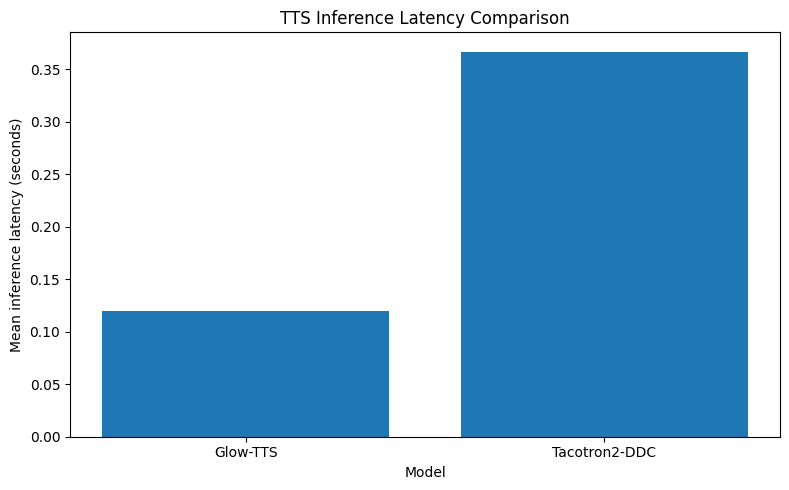

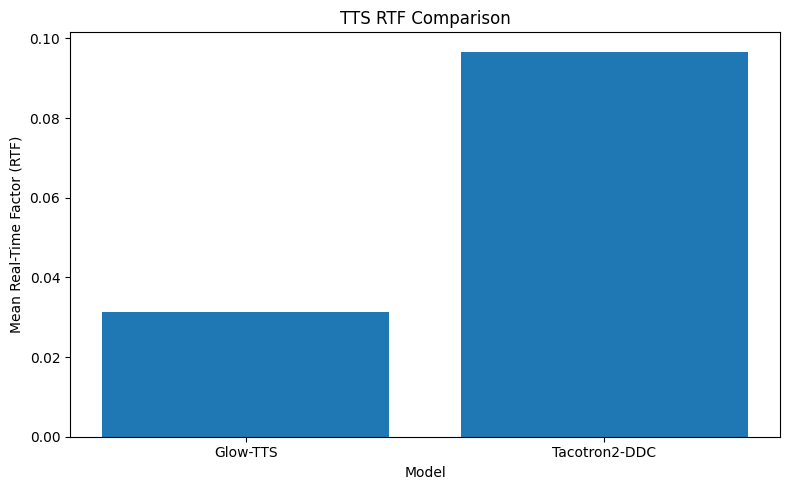

In [7]:
import matplotlib.pyplot as plt

plot_df = summary_df.sort_values("model")

plt.figure(figsize=(8, 5))
plt.bar(plot_df["model"], plot_df["mean_latency_sec"])
plt.ylabel("Mean inference latency (seconds)")
plt.xlabel("Model")
plt.title("TTS Inference Latency Comparison")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(plot_df["model"], plot_df["mean_rtf"])
plt.ylabel("Mean Real-Time Factor (RTF)")
plt.xlabel("Model")
plt.title("TTS RTF Comparison")
plt.tight_layout()
plt.show()

## Experiment 2: Glow-TTS CPU vs GPU Comparison

This experiment compares the inference performance of pretrained
Glow-TTS on CPU and GPU using the same five test sentences.

Each sentence is generated three times after warm-up. The
results include mean inference latency and RTF.

The purpose is to investigate the effect of hardware acceleration
on inference performance.

In [8]:
import time
import gc
import numpy as np
import pandas as pd
import torch
from TTS.api import TTS

MODEL_NAME = "tts_models/en/ljspeech/glow-tts"
N_REPEATS = 3

# Reuse your existing TEST_SENTENCES if already defined.
TEST_SENTENCES = [
    "The quick brown fox jumps over the lazy dog.",
    "Hello, welcome to our text to speech experiment.",
    "Today is a beautiful day to learn something new.",
    "Artificial intelligence can transform written text into speech.",
    "Please read this sentence clearly and naturally."
]

def run_device_experiment(device):
    print(f"\nTesting device: {device}")

    tts = TTS(
        model_name=MODEL_NAME,
        progress_bar=True
    ).to(device)

    sample_rate = int(tts.synthesizer.output_sample_rate)
    records = []

    def sync():
        if device == "cuda":
            torch.cuda.synchronize()

    # Warm-up; not included in measured results.
    _ = tts.tts(text=TEST_SENTENCES[0])
    sync()

    for sentence_id, sentence in enumerate(TEST_SENTENCES, start=1):
        latencies = []
        durations = []
        rtfs = []

        for repeat in range(1, N_REPEATS + 1):
            sync()
            start = time.perf_counter()

            audio = np.asarray(
                tts.tts(text=sentence),
                dtype=np.float32
            ).reshape(-1)

            sync()
            latency = time.perf_counter() - start

            if len(audio) == 0 or not np.isfinite(audio).all():
                raise ValueError(
                    f"Invalid audio: {device}, sentence {sentence_id}"
                )

            duration = len(audio) / sample_rate

            latencies.append(latency)
            durations.append(duration)
            rtfs.append(latency / duration)

        records.append({
            "device": device,
            "sentence_id": sentence_id,
            "latency_mean_sec": np.mean(latencies),
            "latency_std_sec": np.std(latencies, ddof=1),
            "audio_duration_sec": np.mean(durations),
            "rtf_mean": np.mean(rtfs)
        })

        print(
            f"Sentence {sentence_id}: "
            f"latency={np.mean(latencies):.4f}s, "
            f"RTF={np.mean(rtfs):.4f}"
        )

    del tts
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return records


device_records = []

# Run CPU first, then GPU to keep GPU memory use manageable.
device_records.extend(run_device_experiment("cpu"))

if torch.cuda.is_available():
    device_records.extend(run_device_experiment("cuda"))

device_df = pd.DataFrame(device_records)

device_summary = (
    device_df.groupby("device", as_index=False)
    .agg(
        num_sentences=("sentence_id", "nunique"),
        mean_latency_sec=("latency_mean_sec", "mean"),
        mean_audio_duration_sec=("audio_duration_sec", "mean"),
        mean_rtf=("rtf_mean", "mean")
    )
    .round(4)
)

print("\n=== Device Comparison ===")
display(device_summary)

print("\n=== Sentence-Level Results ===")
display(device_df.round(4))

device_df.to_csv(
    "/content/device_comparison_detailed.csv",
    index=False
)
device_summary.to_csv(
    "/content/device_comparison_summary.csv",
    index=False
)

expected_devices = {"cpu"}

if torch.cuda.is_available():
    expected_devices.add("cuda")

assert set(device_summary["device"]) == expected_devices

assert (device_summary["num_sentences"] == len(TEST_SENTENCES)).all()

print("Device comparison completed successfully.")


Testing device: cpu


Sentence 1: latency=0.4195s, RTF=0.1125
Sentence 2: latency=0.5358s, RTF=0.1446
Sentence 3: latency=0.2923s, RTF=0.0789
Sentence 4: latency=0.4622s, RTF=0.0919
Sentence 5: latency=0.3126s, RTF=0.0900



Testing device: cuda


Sentence 1: latency=0.0570s, RTF=0.0153
Sentence 2: latency=0.0541s, RTF=0.0146
Sentence 3: latency=0.0535s, RTF=0.0144
Sentence 4: latency=0.0602s, RTF=0.0120
Sentence 5: latency=0.0566s, RTF=0.0163

=== Device Comparison ===


,device,num_sentences,mean_latency_sec,mean_audio_duration_sec,mean_rtf
0,cpu,5,0.4045,3.9272,0.1036
1,cuda,5,0.0563,3.9272,0.0145



=== Sentence-Level Results ===


,device,sentence_id,latency_mean_sec,latency_std_sec,audio_duration_sec,rtf_mean
0,cpu,1,0.4195,0.2145,3.7275,0.1125
1,cpu,2,0.5358,0.2763,3.7043,0.1446
2,cpu,3,0.2923,0.0076,3.7043,0.0789
3,cpu,4,0.4622,0.0913,5.0278,0.0919
4,cpu,5,0.3126,0.0538,3.4721,0.0900
5,cuda,1,0.0570,0.0011,3.7275,0.0153
6,cuda,2,0.0541,0.0010,3.7043,0.0146
7,cuda,3,0.0535,0.0005,3.7043,0.0144
8,cuda,4,0.0602,0.0002,5.0278,0.0120
9,cuda,5,0.0566,0.0053,3.4721,0.0163


Device comparison completed successfully.
